<a href="https://colab.research.google.com/github/sonakshigupta29/e2e-mass-regression-cmssw/blob/main/01_data_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/e2e_mass_regression'
os.makedirs(BASE, exist_ok=True)

Mounted at /content/drive


In [2]:
!wget -c --content-disposition -O /content/top_gun_opendata_0.parquet "https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet"
!ls -lh /content/top_gun_opendata_0.parquet

--2026-11-24 05:42:18--  https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet
Resolving cernbox.cern.ch (cernbox.cern.ch)... 128.142.53.28, 188.185.200.39, 188.184.19.133, ...
Connecting to cernbox.cern.ch (cernbox.cern.ch)|128.142.53.28|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1171158319 (1.1G) [application/octet-stream]
--2026-11-24 05:42:19--  https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet
Reusing existing connection to cernbox.cern.ch:443.
HTTP request sent, awaiting response... 200 OK
Length: 1171158319 (1.1G) [application/octet-stream]
Saving to: ‘/content/top_gun_opendata_0.parquet’

/content/top_gun_op 100%[===================>]   1.09G  17.7MB/s    in 53s     

2026-11-24 05:43:13 (21.0 MB/s) - ‘/content/top_gun_opendata_0.parquet’ saved [1171158319/1171158319]

-rw-r--r-- 1 root root 1.1G Feb 23  2024 /content/top_gun_opendata_0.parquet


In [3]:
!cp /content/top_gun_opendata_0.parquet /content/drive/MyDrive/e2e_mass_regression/

In [4]:
import pyarrow.parquet as pq
pf = pq.ParquetFile(f'{BASE}/top_gun_opendata_0.parquet')
print(pf.metadata.num_rows, pf.metadata.num_row_groups)
print(pf.schema_arrow)

150327 150327
X_jet: list<item: list<item: list<item: double>>>
  child 0, item: list<item: list<item: double>>
      child 0, item: list<item: double>
          child 0, item: double
m: double
iphi: double
pt: double
ieta: double


150327 85.28666687011719 499.9996643066406 293.28993698248314 292.99078369140625 119.90458159601208
NaN: 0


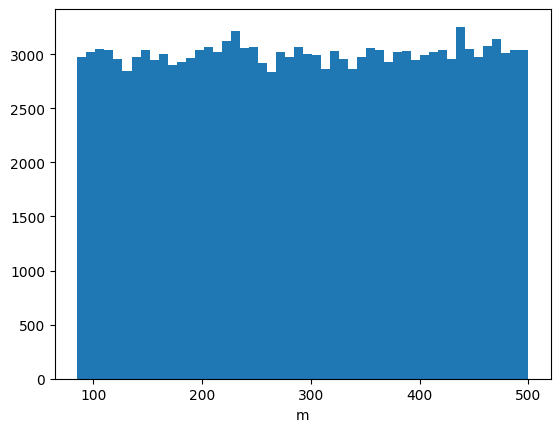

(8, 125, 125)
0 0.0 56.258026 0.00224
1 -485.9448 22.394949 0.001088
2 -84.91347 312.55505 0.001408
3 0.0 72.8135 0.041344
4 0.0 18.54857 0.0048
5 0.0 2.0 0.002496
6 0.0 3.0 0.00224
7 0.0 3.0 0.002816


In [5]:
import numpy as np, matplotlib.pyplot as plt

# Part 5: the target, for the whole file (cheap)
t = pf.read(columns=['m']).to_pandas()['m'].values
print(len(t), t.min(), t.max(), t.mean(), np.median(t), t.std())
print('NaN:', np.isnan(t).sum())
plt.hist(t, bins=50); plt.xlabel('m'); plt.savefig('mass_hist.png'); plt.show()

# Part 4: one sample
rg = pf.read_row_group(0).to_pandas()
x = np.array([[list(row) for row in ch] for ch in rg['X_jet'].values[0]], dtype=np.float32)
print(x.shape)
for c in range(x.shape[0]):
    print(c, x[c].min(), x[c].max(), (x[c] > 0).mean())

In [6]:
!cp mass_hist.png "{BASE}/mass_hist.png"
!ls -lh "{BASE}/mass_hist.png"

-rw------- 1 root root 11K Nov 24 05:55 /content/drive/MyDrive/e2e_mass_regression/mass_hist.png
